First 5 Rows
         Date        Time State     Group  Unit  Sales
0  1-Oct-2020     Morning    WA      Kids     8  20000
1  1-Oct-2020     Morning    WA       Men     8  20000
2  1-Oct-2020     Morning    WA     Women     4  10000
3  1-Oct-2020     Morning    WA   Seniors    15  37500
4  1-Oct-2020   Afternoon    WA      Kids     3   7500

Dataset Info
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7560 entries, 0 to 7559
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   Date    7560 non-null   object
 1   Time    7560 non-null   object
 2   State   7560 non-null   object
 3   Group   7560 non-null   object
 4   Unit    7560 non-null   int64 
 5   Sales   7560 non-null   int64 
dtypes: int64(2), object(4)
memory usage: 354.5+ KB
None

Missing Values
Date     0
Time     0
State    0
Group    0
Unit     0
Sales    0
dtype: int64

Non Missing Values
Date     7560
Time     7560
State    7560
Group    7560
Unit     7560
Sales  

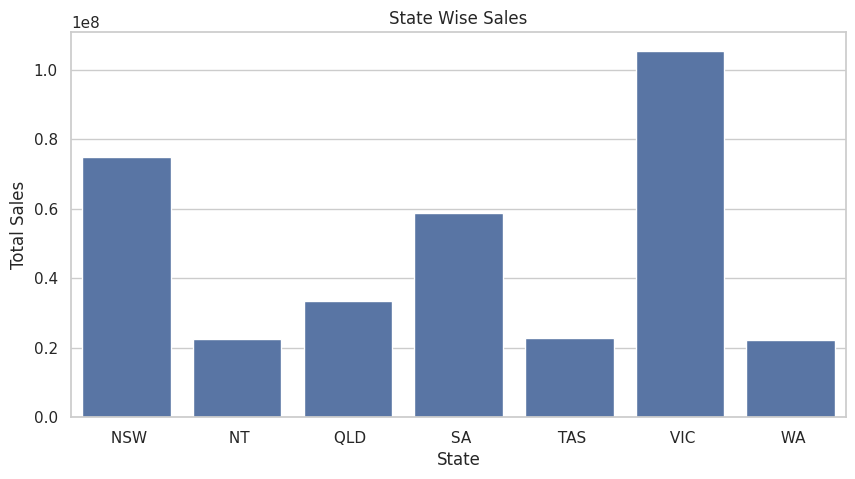

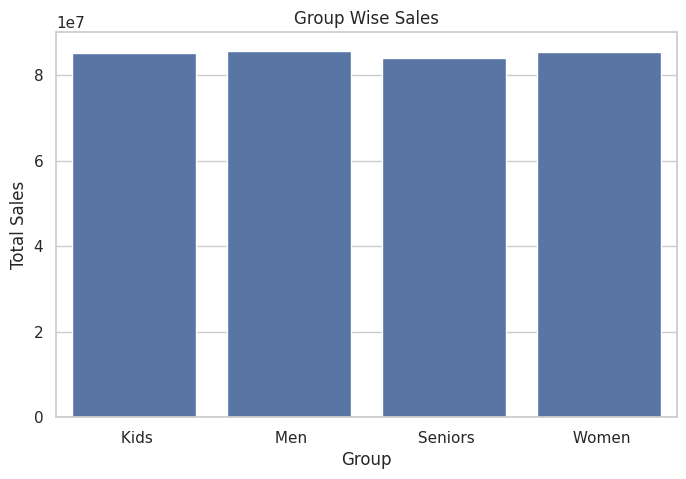

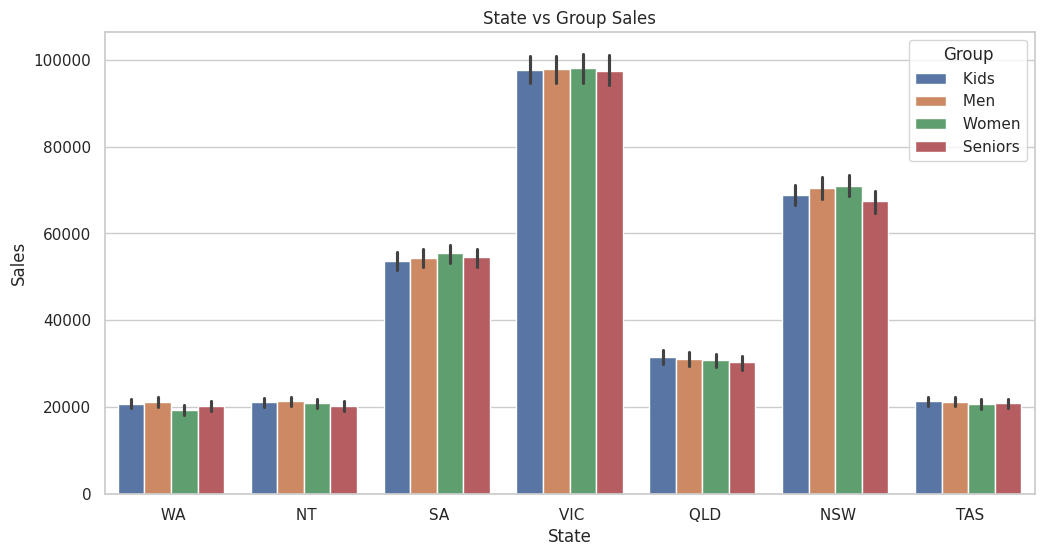

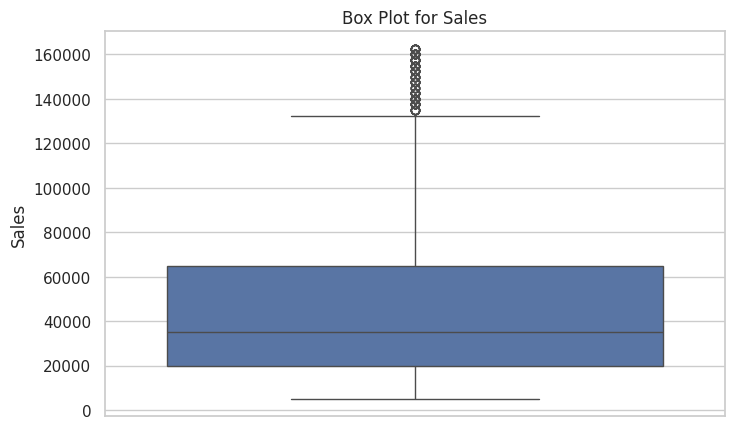

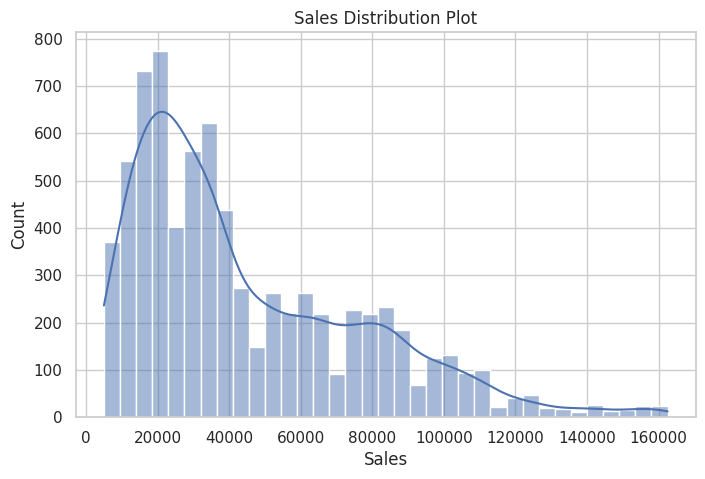

/tmp/ipykernel_1615/1403665187.py:253: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df["Hour"] = pd.to_datetime(df["Time"]).dt.hour


DateParseError: Unknown datetime string format, unable to parse:  Morning, at position 0

In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


pd.set_option('display.max_columns', None)


# 1. LOAD DATA


# Load CSV File
df = pd.read_csv("/content/AusApparalSales4thQrt2020.csv")

# Display first 5 rows
print("First 5 Rows")
print(df.head())


print("\nDataset Info")
print(df.info())


# 2. DATA WRANGLING


# Check Missing Values
print("\nMissing Values")
print(df.isna().sum())

# Check Non-Missing Values
print("\nNon Missing Values")
print(df.notna().sum())

# Remove duplicate rows if any
df = df.drop_duplicates()

# Fill missing numeric values with mean
numeric_cols = df.select_dtypes(include=np.number).columns

for col in numeric_cols:
    df[col] = df[col].fillna(df[col].mean())

# Fill missing categorical values with mode
categorical_cols = df.select_dtypes(include='object').columns

for col in categorical_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

print("\nMissing Values After Treatment")
print(df.isna().sum())


# 3. NORMALIZATION


# Min-Max Normalization
# Formula:
# (x - min) / (max - min)

for col in numeric_cols:
    df[col + "_Normalized"] = (
        (df[col] - df[col].min()) /
        (df[col].max() - df[col].min())
    )

print("\nNormalized Data")
print(df.head())

# 4. GROUPBY ANALYSIS


# State-wise total sales
state_sales = df.groupby("State")["Sales"].sum()

print("\nState Wise Sales")
print(state_sales)

# Group-wise sales
group_sales = df.groupby("Group")["Sales"].sum()

print("\nGroup Wise Sales")
print(group_sales)


# 5. STATISTICS


print("\nDescriptive Statistics for Sales")

print("Mean :", df["Sales"].mean())
print("Median :", df["Sales"].median())
print("Mode :", df["Sales"].mode()[0])
print("Standard Deviation :", df["Sales"].std())

print("\nDescriptive Statistics for Units")

print("Mean :", df["Unit"].mean())
print("Median :", df["Unit"].median())
print("Mode :", df["Unit"].mode()[0])
print("Standard Deviation :", df["Unit"].std())


# 6. HIGHEST AND LOWEST SALES


# Highest Sales State
highest_state = state_sales.idxmax()
lowest_state = state_sales.idxmin()

print("\nHighest Sales State :", highest_state)
print("Lowest Sales State :", lowest_state)

# Highest Sales Group
highest_group = group_sales.idxmax()
lowest_group = group_sales.idxmin()

print("\nHighest Sales Group :", highest_group)
print("Lowest Sales Group :", lowest_group)


# 7. DATE CONVERSION


# Convert Date column into datetime format
df["Date"] = pd.to_datetime(df["Date"])

# Set Date as index
df.set_index("Date", inplace=True)


# 8. WEEKLY, MONTHLY & QUARTERLY REPORTS


# Weekly Report
weekly_report = df.resample('W')["Sales"].sum()

print("\nWeekly Sales Report")
print(weekly_report)

# Monthly Report
monthly_report = df.resample('ME')["Sales"].sum() # Changed 'M' to 'ME'

print("\nMonthly Sales Report")
print(monthly_report)

# Quarterly Report
quarterly_report = df.resample('QE')["Sales"].sum() # Changed 'Q' to 'QE'

print("\nQuarterly Sales Report")
print(quarterly_report)


# 9. DATA VISUALIZATION


sns.set(style="whitegrid")


# State Wise Sales


plt.figure(figsize=(10,5))

sns.barplot(
    x=state_sales.index,
    y=state_sales.values
)

plt.title("State Wise Sales")
plt.xlabel("State")
plt.ylabel("Total Sales")

plt.show()


# Group Wise Sales


plt.figure(figsize=(8,5))

sns.barplot(
    x=group_sales.index,
    y=group_sales.values
)

plt.title("Group Wise Sales")
plt.xlabel("Group")
plt.ylabel("Total Sales")

plt.show()


# State vs Group Sales


plt.figure(figsize=(12,6))

sns.barplot(
    data=df.reset_index(),
    x="State",
    y="Sales",
    hue="Group"
)

plt.title("State vs Group Sales")

plt.show()


# Box Plot for Sales


plt.figure(figsize=(8,5))

sns.boxplot(y=df["Sales"])

plt.title("Box Plot for Sales")

plt.show()


# Distribution Plot for Sales


plt.figure(figsize=(8,5))

sns.histplot(df["Sales"], kde=True)

plt.title("Sales Distribution Plot")

plt.show()


# 10. TIME OF DAY ANALYSIS


# Create Time Periods

# Assuming 'Time' column exists


if "Time" in df.columns:

    df["Hour"] = pd.to_datetime(df["Time"]).dt.hour

    def sales_period(hour):

        if hour < 12:
            return "Morning"

        elif hour < 17:
            return "Afternoon"

        else:
            return "Evening"

    df["Time_Period"] = df["Hour"].apply(sales_period)

    period_sales = df.groupby("Time_Period")["Sales"].sum()

    plt.figure(figsize=(8,5))

    sns.barplot(
        x=period_sales.index,
        y=period_sales.values
    )

    plt.title("Time of Day Sales Analysis")

    plt.show()


# 11. DAILY SALES CHART


daily_sales = df.resample('D')["Sales"].sum()

plt.figure(figsize=(12,5))

daily_sales.plot()

plt.title("Daily Sales Trend")
plt.xlabel("Date")
plt.ylabel("Sales")

plt.show()


# 12. WEEKLY SALES CHART


plt.figure(figsize=(12,5))

weekly_report.plot()

plt.title("Weekly Sales Trend")
plt.xlabel("Week")
plt.ylabel("Sales")

plt.show()


# 13. MONTHLY SALES CHART


plt.figure(figsize=(12,5))

monthly_report.plot()

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Sales")

plt.show()


# 14. QUARTERLY SALES CHART


plt.figure(figsize=(12,5))

quarterly_report.plot()

plt.title("Quarterly Sales Trend")
plt.xlabel("Quarter")
plt.ylabel("Sales")

plt.show()


# 15. RECOMMENDATIONS


print("\nRecommendations")

print("""
1. Focus more marketing campaigns on low-performing states.

2. Increase promotional offers for low sales groups.

3. Use peak sales periods for targeted advertisements.

4. Improve stock availability in high-performing states.

5. Seaborn is recommended because:
   - Easy statistical visualization
   - Attractive graphs
   - Better integration with Pandas
   - Useful for distribution and box plots
""")